<a href="https://colab.research.google.com/github/JVV06/Synth-dataset/blob/main/EDA_final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# ============================================================================
# TabLabour — STEP 1: Data Loading & Exploratory Data Analysis
# QLFS_combined_FINAL.csv (2025 Q4 + 2026 Q1)
# ============================================================================
# Upload QLFS_combined_FINAL.csv directly via Colab file sidebar then run.
# ============================================================================

# ── 0. Install & import ──────────────────────────────────────────────────────
!pip install missingno -q

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import missingno as msno
import warnings
warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:.2f}".format)
plt.rcParams.update({"figure.dpi": 130, "font.family": "DejaVu Sans"})

PALETTE = {"2025Q4": "#1F3864", "2026Q1": "#E05C2A"}

In [ ]:
# ── 1. Upload ─────────────────────────────────────────────────────────────────
from google.colab import files
print("Upload: QLFS_combined_FINAL.csv")
uploaded = files.upload()
FILE_PATH = list(uploaded.keys())[0]

df = pd.read_csv(FILE_PATH, low_memory=False, sep=';')
print(f"\nLoaded: {df.shape[0]:,} rows × {df.shape[1]} columns")

Upload: QLFS_combined_FINAL.csv


Saving QLFS_combined_FINAL.csv to QLFS_combined_FINAL.csv

Loaded: 126,083 rows × 201 columns


In [ ]:
# ── 2. Confirm wave structure ─────────────────────────────────────────────────
print("\n" + "="*65)
print("WAVE COVERAGE")
print("="*65)
print(df["wave_label"].value_counts().sort_index().to_string())
assert set(df["wave_label"].unique()) == {"2025Q4","2026Q1"}, \
    "Unexpected wave values — check file."
print("✓ Both waves confirmed, zero nulls in wave_label.")


WAVE COVERAGE
wave_label
2025Q4    63264
2026Q1    62819
✓ Both waves confirmed, zero nulls in wave_label.


In [ ]:
# ── 3. Schema overview ────────────────────────────────────────────────────────
print("\n" + "="*65)
print("SCHEMA OVERVIEW")
print("="*65)
print(f"Total columns : {df.shape[1]}")
print(f"Numeric cols  : {df.select_dtypes(include=np.number).shape[1]}")
print(f"String cols   : {df.select_dtypes(include='object').shape[1]}")
print(f"\nFirst 5 rows:")
print(df[["wave_label","Province","Q13GENDER","Q14AGE",
          "Q17EDUCATION","Lfs_Status","Sector","Weight"]].head())



SCHEMA OVERVIEW
Total columns : 201
Numeric cols  : 52
String cols   : 149

First 5 rows:
  wave_label      Province Q13GENDER  Q14AGE Q17EDUCATION Lfs_Status  \
0     2025Q4  Western Cape      Male      29           17   Employed   
1     2025Q4  Western Cape    Female      27           26   Employed   
2     2025Q4  Western Cape      Male       1           98        NaN   
3     2025Q4  Western Cape    Female      48           12   Employed   
4     2025Q4  Western Cape    Female       9            2        NaN   

          Sector  Weight  
0  Formal sector 3393.66  
1  Formal sector 3393.66  
2            NaN 3393.66  
3  Formal sector 1382.70  
4            NaN 1382.70  



SAMPLE SIZE BY WAVE × PROVINCE
wave_label     2025Q4  2026Q1
Province                     
Eastern Cape    11137    5044
Free State       3676    2542
Gauteng         13658    9176
KwaZulu-Natal    4214    7171
Limpopo          8089    4472
Mpumalanga       2633    3383
North West       5507    2388
Northern Cape    7786    1703
Western Cape     6564    4667


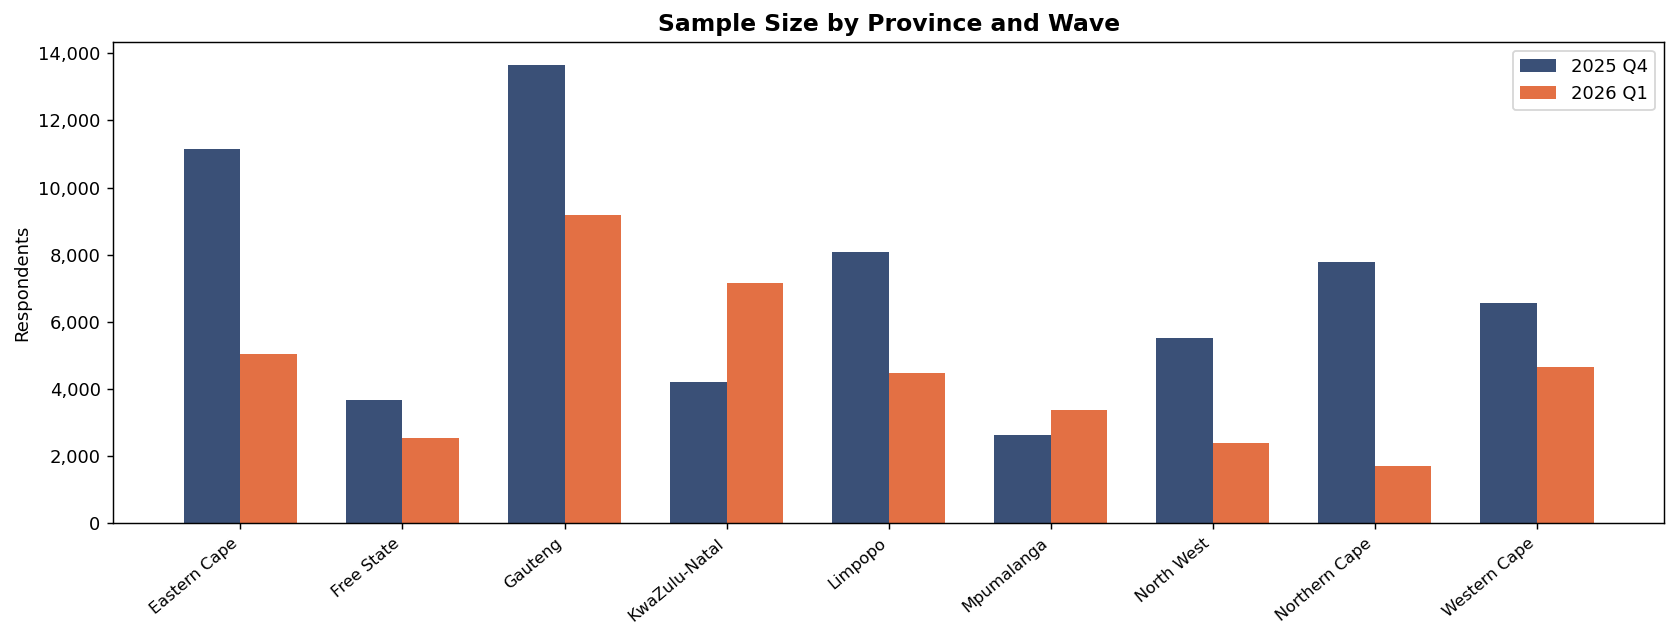

Saved: fig1_sample_by_province.png


In [ ]:
# ── 4. Sample size by wave × province ─────────────────────────────────────────
print("\n" + "="*65)
print("SAMPLE SIZE BY WAVE × PROVINCE")
print("="*65)
prov_wave = (df.dropna(subset=["Province"])
               .groupby(["wave_label","Province"])
               .size()
               .unstack(level=0)
               .fillna(0)
               .astype(int)
               .sort_index())
print(prov_wave.to_string())

fig, ax = plt.subplots(figsize=(13, 5))
x     = np.arange(len(prov_wave))
width = 0.35
ax.bar(x - width/2, prov_wave.get("2025Q4", 0),
       width, label="2025 Q4", color=PALETTE["2025Q4"], alpha=0.88)
ax.bar(x + width/2, prov_wave.get("2026Q1", 0),
       width, label="2026 Q1", color=PALETTE["2026Q1"], alpha=0.88)
ax.set_xticks(x)
ax.set_xticklabels(prov_wave.index, rotation=40, ha="right", fontsize=9)
ax.set_title("Sample Size by Province and Wave", fontweight="bold", fontsize=13)
ax.set_ylabel("Respondents")
ax.legend()
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v,_: f"{int(v):,}"))
plt.tight_layout()
plt.savefig("fig1_sample_by_province.png", dpi=150)
plt.show()
print("Saved: fig1_sample_by_province.png")


LABOUR FORCE STATUS (Lfs_Status)
Lfs_Status  Employed  Unemployed  Discouraged jobseekers  Available jobseekers  Unavailable jobseekers  Other outside the labour force
wave_label                                                                                                                            
2025Q4         34.40       15.80                    7.80                  1.90                    0.10                           40.00
2026Q1         34.80       18.60                    9.20                  2.40                    0.10                           34.80


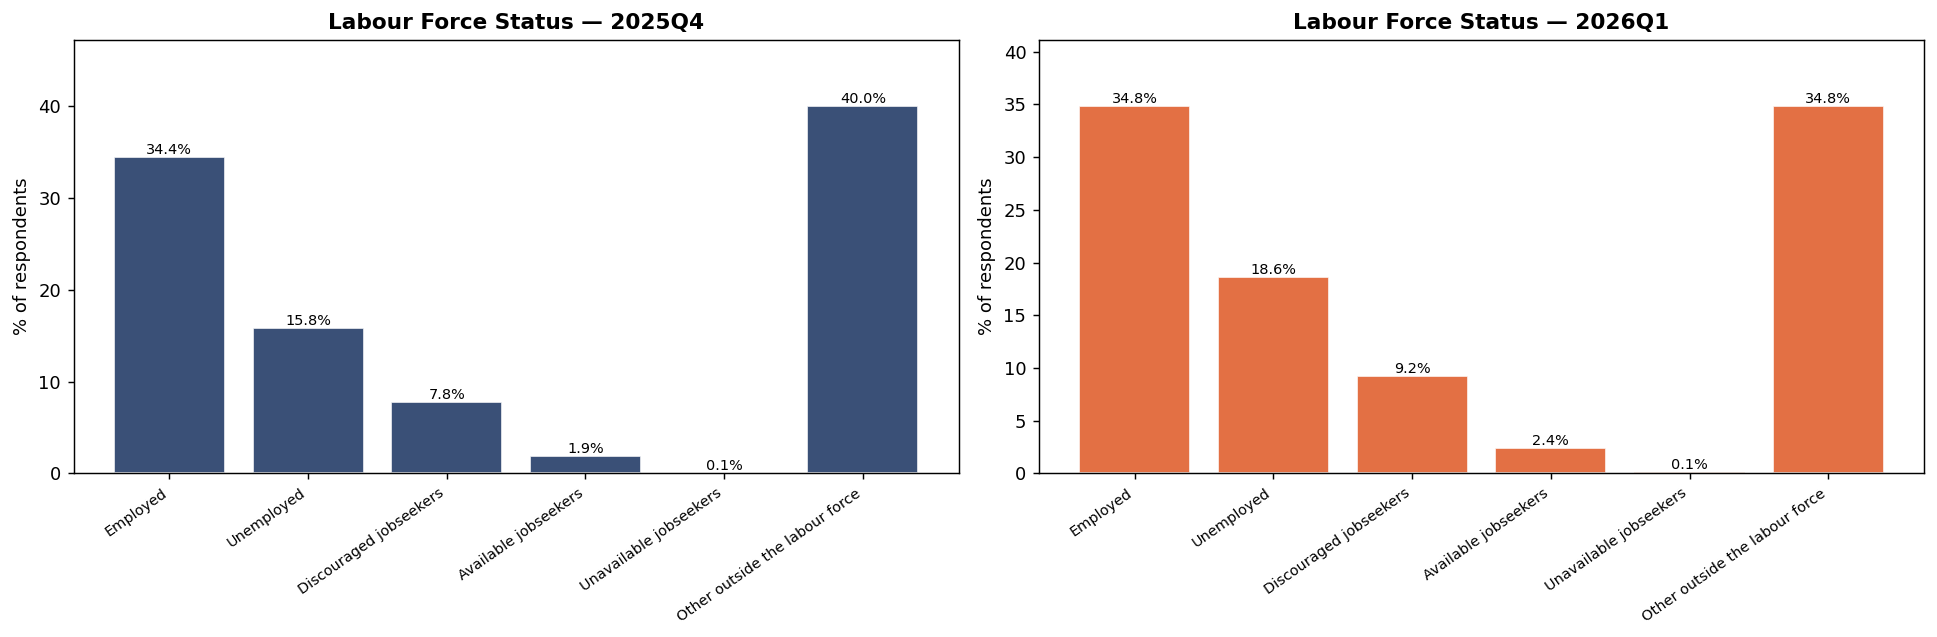

Saved: fig2_lfs_status.png


In [ ]:
# ── 5. Labour force status distribution ──────────────────────────────────────
print("\n" + "="*65)
print("LABOUR FORCE STATUS (Lfs_Status)")
print("="*65)
lfs_order = ["Employed","Unemployed","Discouraged jobseekers",
             "Available jobseekers","Unavailable jobseekers",
             "Other outside the labour force"]
lfs = (df.dropna(subset=["Lfs_Status"])
         .groupby(["wave_label","Lfs_Status"])
         .size()
         .unstack(fill_value=0))
lfs_pct = lfs.div(lfs.sum(axis=1), axis=0) * 100
# reorder columns to logical order
lfs_pct = lfs_pct.reindex(columns=[c for c in lfs_order if c in lfs_pct.columns])
print(lfs_pct.round(1).to_string())

fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=False)
for i, wave in enumerate(["2025Q4","2026Q1"]):
    if wave not in lfs_pct.index:
        continue
    row  = lfs_pct.loc[wave]
    bars = axes[i].bar(range(len(row)), row.values,
                       color=PALETTE[wave], alpha=0.88, edgecolor="white")
    axes[i].set_title(f"Labour Force Status — {wave}", fontweight="bold")
    axes[i].set_ylabel("% of respondents")
    axes[i].set_xticks(range(len(row)))
    axes[i].set_xticklabels(row.index, rotation=35, ha="right", fontsize=8)
    axes[i].set_ylim(0, row.values.max() * 1.18)
    for j, v in enumerate(row.values):
        axes[i].text(j, v + 0.3, f"{v:.1f}%", ha="center", fontsize=8)
plt.tight_layout()
plt.savefig("fig2_lfs_status.png", dpi=150)
plt.show()
print("Saved: fig2_lfs_status.png")


In [ ]:
# ── 6. Weighted unemployment rates ───────────────────────────────────────────
print("\n" + "="*65)
print("UNEMPLOYMENT RATES (survey-weighted)")
print("="*65)
for wave, grp in df.groupby("wave_label"):
    grp = grp.dropna(subset=["Lfs_Status","Weight"])
    lf      = grp[grp["Lfs_Status"].isin(["Employed","Unemployed"])]
    unempl  = grp[grp["Lfs_Status"] == "Unemployed"]
    broad   = grp[grp["Lfs_Status"].isin(["Employed","Unemployed","Discouraged jobseekers"])]
    broad_u = grp[grp["Lfs_Status"].isin(["Unemployed","Discouraged jobseekers"])]
    narrow  = unempl["Weight"].sum() / lf["Weight"].sum() * 100 if lf["Weight"].sum() > 0 else np.nan
    broad_r = broad_u["Weight"].sum() / broad["Weight"].sum() * 100 if broad["Weight"].sum() > 0 else np.nan
    print(f"  {wave}:  Narrow = {narrow:.1f}%   Broad (incl. discouraged) = {broad_r:.1f}%")



UNEMPLOYMENT RATES (survey-weighted)
  2025Q4:  Narrow = 31.2%   Broad (incl. discouraged) = 40.1%
  2026Q1:  Narrow = 51.9%   Broad (incl. discouraged) = 61.7%



AGE DISTRIBUTION
              count  mean   std  min   25%   50%   75%    max
wave_label                                                   
2025Q4     63264.00 31.20 21.20 0.00 13.00 28.00 46.00 115.00
2026Q1     62819.00 31.30 21.20 0.00 13.00 28.00 46.00 115.00


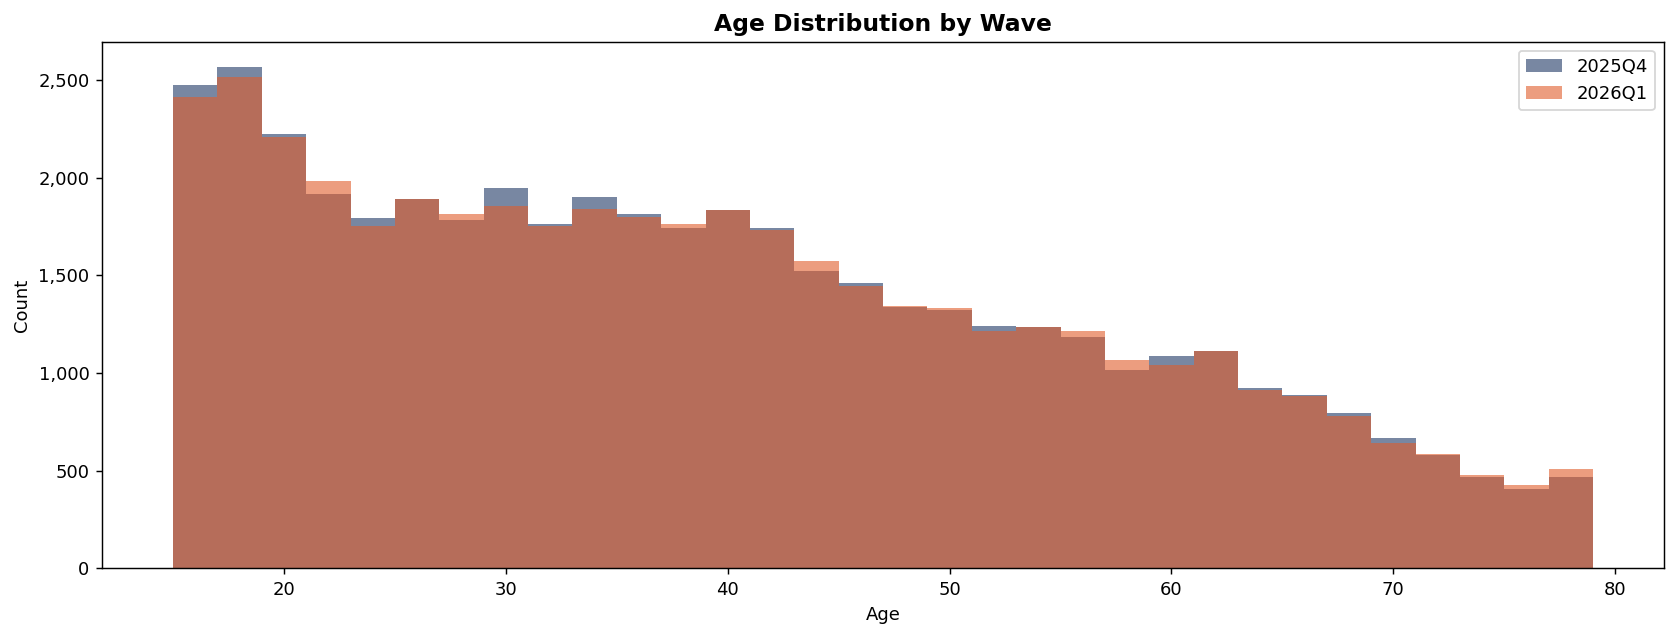

Saved: fig3_age_distribution.png


In [ ]:
# ── 7. Age distribution ───────────────────────────────────────────────────────
print("\n" + "="*65)
print("AGE DISTRIBUTION")
print("="*65)
print(df.groupby("wave_label")["Q14AGE"].describe().round(1).to_string())

fig, ax = plt.subplots(figsize=(13, 5))
for wave, grp in df.groupby("wave_label"):
    ax.hist(grp["Q14AGE"].dropna(), bins=range(15, 80, 2),
            alpha=0.6, label=wave, color=PALETTE[wave], edgecolor="none")
ax.set_title("Age Distribution by Wave", fontweight="bold", fontsize=13)
ax.set_xlabel("Age")
ax.set_ylabel("Count")
ax.legend()
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v,_: f"{int(v):,}"))
plt.tight_layout()
plt.savefig("fig3_age_distribution.png", dpi=150)
plt.show()
print("Saved: fig3_age_distribution.png")



EDUCATION (Q17EDUCATION) — top 10 categories
Q17EDUCATION  Grade 12/Standard 10/Form 5/Matric (No Exemption)    12    98  No schooling  Grade 11/Standard 9/Form 4    11  Grade 10/Standard 8/Form 3   10  Grade 9/Standard 7/Form 2/AET 4    9
wave_label                                                                                                                                                                                        
2025Q4                                                     0.00 18.20 12.70          0.00                        0.00 10.30                        0.00 8.90                             0.00 6.00
2026Q1                                                    19.00  0.00  0.00         11.50                       10.40  0.00                        9.20 0.00                             6.00 0.00


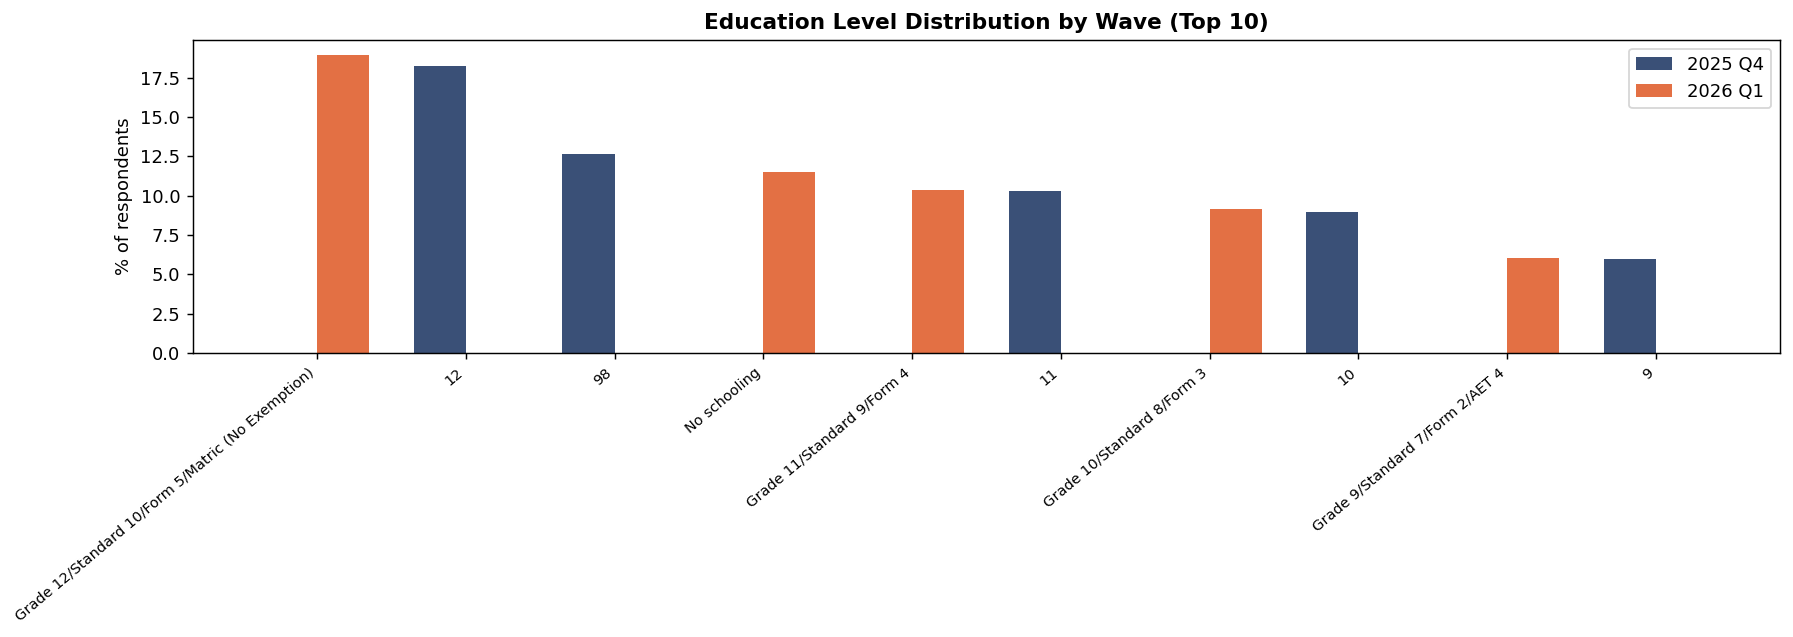

Saved: fig4_education.png

EDUCATION (Q17EDUCATION) — top 10 categories
Q17EDUCATION  Grade 12/Standard 10/Form 5/Matric (No Exemption)    12    98  No schooling  Grade 11/Standard 9/Form 4    11  Grade 10/Standard 8/Form 3   10  Grade 9/Standard 7/Form 2/AET 4    9
wave_label                                                                                                                                                                                        
2025Q4                                                     0.00 18.20 12.70          0.00                        0.00 10.30                        0.00 8.90                             0.00 6.00
2026Q1                                                    19.00  0.00  0.00         11.50                       10.40  0.00                        9.20 0.00                             6.00 0.00


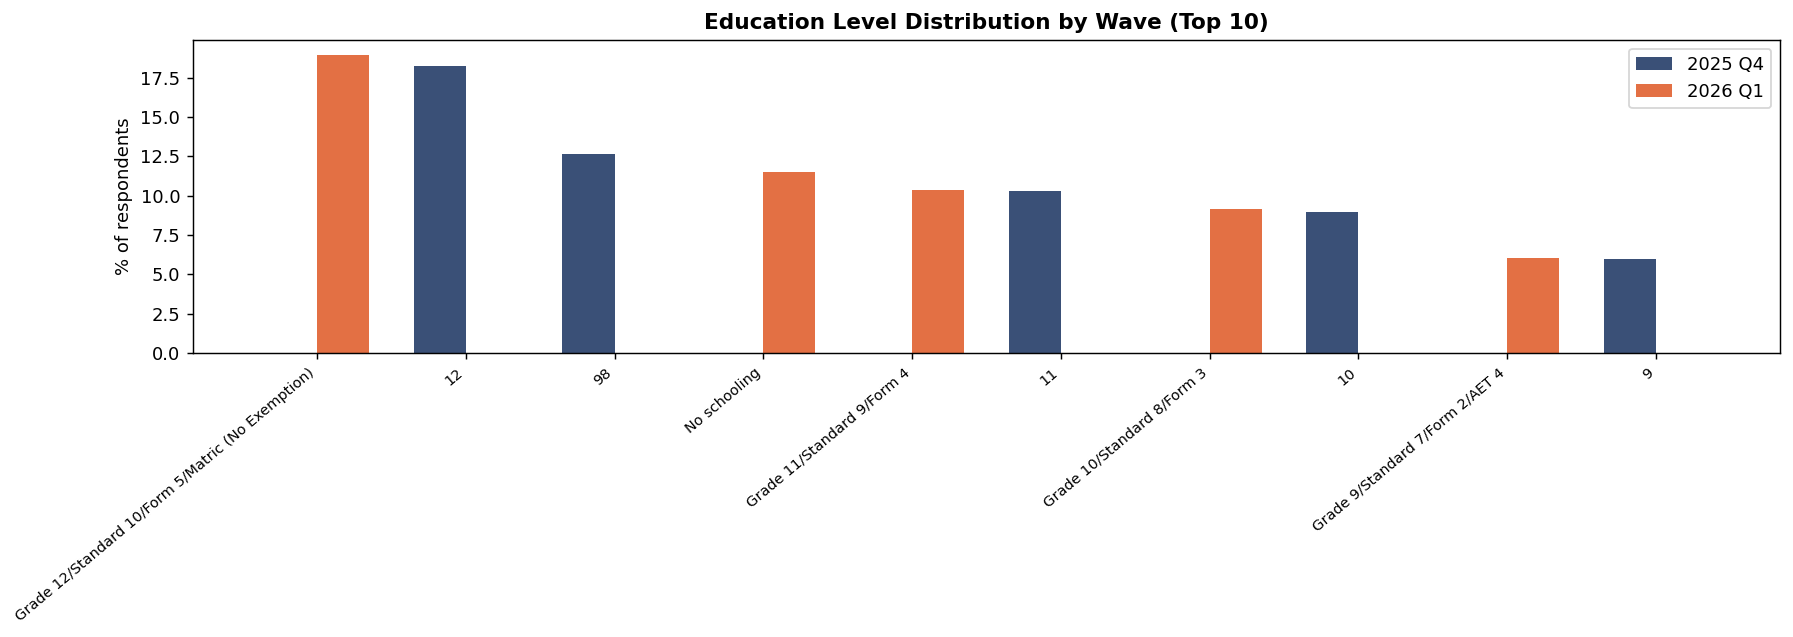

Saved: fig4_education.png


In [ ]:
# ── 8. Education distribution ─────────────────────────────────────────────────
print("\n" + "="*65)
print("EDUCATION (Q17EDUCATION) — top 10 categories")
print("="*65)
edu = (df.dropna(subset=["Q17EDUCATION"])
         .groupby(["wave_label","Q17EDUCATION"])
         .size()
         .unstack(fill_value=0))
edu_pct = edu.div(edu.sum(axis=1), axis=0) * 100

# Show top 10 categories by combined frequency
top10 = (edu_pct.sum().sort_values(ascending=False).head(10).index)
edu_top = edu_pct[top10]
print(edu_top.round(1).to_string())

fig, ax = plt.subplots(figsize=(14, 5))
x     = np.arange(len(top10))
width = 0.35
ax.bar(x - width/2, edu_top.loc["2025Q4"] if "2025Q4" in edu_top.index else [0]*len(top10),
       width, label="2025 Q4", color=PALETTE["2025Q4"], alpha=0.88)
ax.bar(x + width/2, edu_top.loc["2026Q1"] if "2026Q1" in edu_top.index else [0]*len(top10),
       width, label="2026 Q1", color=PALETTE["2026Q1"], alpha=0.88)
ax.set_xticks(x)
ax.set_xticklabels(top10, rotation=40, ha="right", fontsize=8)
ax.set_title("Education Level Distribution by Wave (Top 10)", fontweight="bold")
ax.set_ylabel("% of respondents")
ax.legend()
plt.tight_layout()
plt.savefig("fig4_education.png", dpi=150)
plt.show()
print("Saved: fig4_education.png")


In [ ]:
# ── 9. Gender distribution ────────────────────────────────────────────────────
print("\n" + "="*65)
print("GENDER DISTRIBUTION")
print("="*65)
gen = (df.dropna(subset=["Q13GENDER"])
         .groupby(["wave_label","Q13GENDER"])
         .size()
         .unstack(fill_value=0))
gen_pct = gen.div(gen.sum(axis=1), axis=0) * 100
print(gen_pct.round(1).to_string())



GENDER DISTRIBUTION
Q13GENDER   Female  Male
wave_label              
2025Q4       52.30 47.70
2026Q1       51.90 48.10


In [ ]:
# ── 10. Sector breakdown (employed respondents only) ─────────────────────────
print("\n" + "="*65)
print("SECTOR (employed respondents only)")
print("="*65)
employed = df[df["Lfs_Status"] == "Employed"].dropna(subset=["Sector"])
sec = (employed.groupby(["wave_label","Sector"])
               .size()
               .unstack(fill_value=0))
sec_pct = sec.div(sec.sum(axis=1), axis=0) * 100
print(sec_pct.round(1).to_string())



SECTOR (employed respondents only)
Sector      Formal sector  Households  Informal
wave_label                                     
2025Q4              70.60        7.20     22.20
2026Q1              55.00       19.30     25.70


In [ ]:
# ── 11. Industry breakdown (employed, top 8) ──────────────────────────────────
print("\n" + "="*65)
print("INDUSTRY (employed respondents, top 8)")
print("="*65)
ind = (employed.dropna(subset=["Indus"])
               .groupby(["wave_label","Indus"])
               .size()
               .unstack(fill_value=0))
ind_pct = ind.div(ind.sum(axis=1), axis=0) * 100
top8_ind = ind_pct.sum().sort_values(ascending=False).head(8).index
print(ind_pct[top8_ind].round(1).to_string())



INDUSTRY (employed respondents, top 8)
Indus       Wholesale and retail trade  Private households  Manufacturing  Financial intermediation  Community  Construction  Mining and quarrying  Other
wave_label                                                                                                                                               
2025Q4                            0.00               24.30           8.70                     19.90      16.10          8.00                  2.50   7.20
2026Q1                           46.50               19.30          19.90                      0.00       0.00          7.70                  6.50   0.10



MISSINGNESS PROFILE — top 20 columns
Q27OFFSEASON       100.00
Q4213TOTALHRS      100.00
Q4213FRIHRSWRK     100.00
Q4213TUEHRSWRK     100.00
Q4213WEDHRSWRK     100.00
Q4213THUHRSWRK     100.00
Q4213SATHRSWRK     100.00
Q420OTHERHRSWRK    100.00
Q4213MONHRSWRK     100.00
Q4213SUNHRSWRK     100.00
Q27BRECPAY          99.90
Q59ETIME            99.90
Q33AWHNSTART        99.90
Q4212THUHRSWRK      99.90
Q4211SUNHRSWRK      99.90
Q420SECONDHRSWRK    99.90
Q4212FRIHRSWRK      99.90
Q420FIRSTHRSWRK     99.90
Q420TOTALHRSWRK     99.90
Q4212MONHRSWRK      99.90

Columns with 1–50% missing (23) — review for non-response:
at_least_1         41.10
Neet               41.10
Q59BFETCHWATER     34.30
Q59DCONSTRUC       34.30
Q59CPRODHHGOODS    34.30
Q59AFARMWRK        34.30
Status             34.30
Q59ECATCHFOOD      34.30
Lfs_Status         34.30
Q24APDWRK          33.10
Q20SELFRESPOND     33.10
Q111APPRENTICE     33.10
Q112TRAIN          33.10
Education_status   29.30
Graduates          24.50
UQNO   

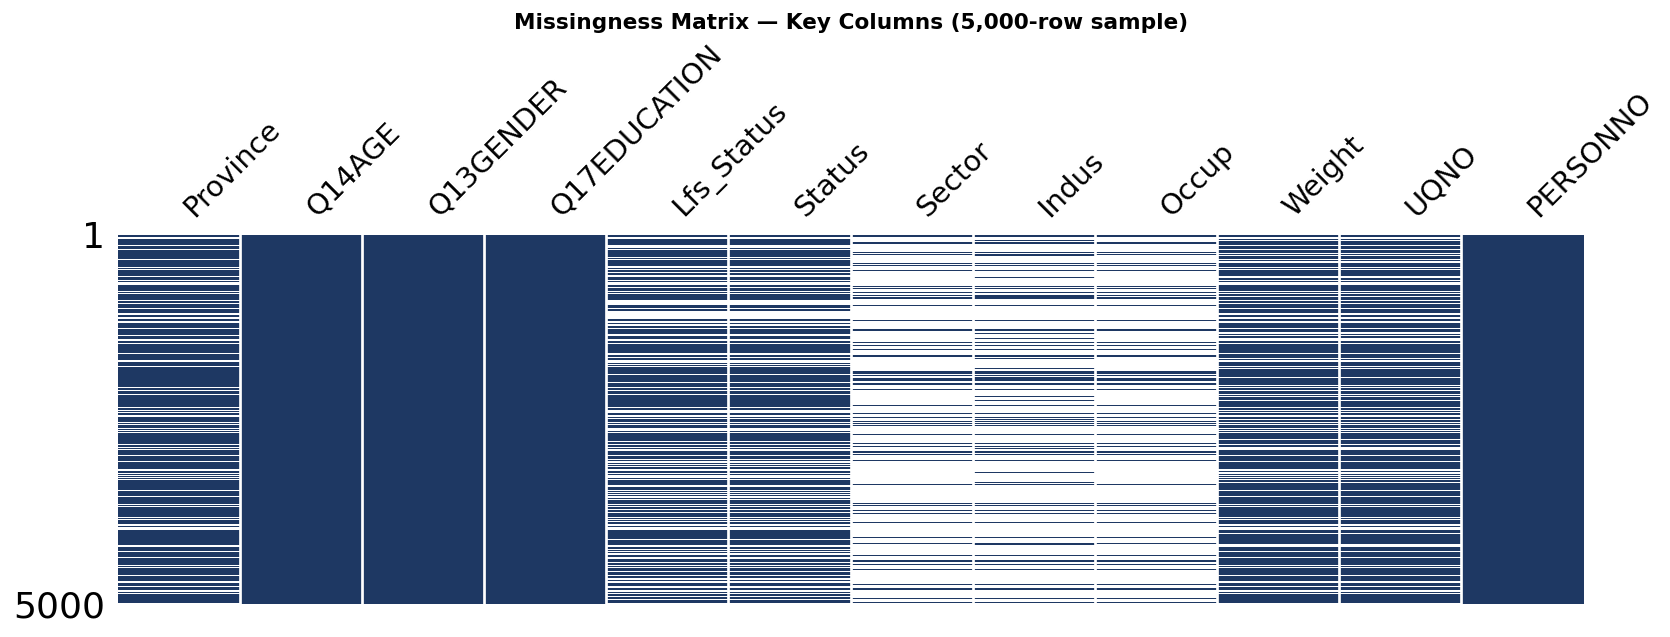

Saved: fig5_missingness.png


In [ ]:
# ── 12. Missingness profile ───────────────────────────────────────────────────
print("\n" + "="*65)
print("MISSINGNESS PROFILE — top 20 columns")
print("="*65)
miss = (df.isna().mean() * 100).sort_values(ascending=False)
print(miss.head(20).round(1).to_string())

# Columns with missingness between 1–50% (non-trivial, non-structural)
medium_miss = miss[(miss > 1) & (miss < 50)]
print(f"\nColumns with 1–50% missing ({len(medium_miss)}) — review for non-response:")
print(medium_miss.round(1).to_string())

# Missingness matrix on a sample
sample = df.sample(min(5000, len(df)), random_state=42)
key_cols = ["Province","Q14AGE","Q13GENDER","Q17EDUCATION","Lfs_Status",
            "Status","Sector","Indus","Occup","Weight","UQNO","PERSONNO"]
fig, ax = plt.subplots(figsize=(13, 5))
msno.matrix(sample[key_cols], ax=ax, sparkline=False,
            color=(0.12, 0.22, 0.39))
ax.set_title("Missingness Matrix — Key Columns (5,000-row sample)",
             fontweight="bold")
plt.tight_layout()
plt.savefig("fig5_missingness.png", dpi=150)
plt.show()
print("Saved: fig5_missingness.png")


In [ ]:
# ── 13. Cardinality of key categoricals ──────────────────────────────────────
print("\n" + "="*65)
print("CARDINALITY OF KEY CATEGORICAL VARIABLES")
print("="*65)
cat_vars = ["Province","Q17EDUCATION","Indus","Occup","Status",
            "Lfs_Status","Sector","Ste_icse18","age_grp1",
            "Education_status","Graduates"]
for col in cat_vars:
    if col in df.columns:
        n = df[col].nunique(dropna=True)
        print(f"  {col:25s} {n:4d} distinct values")



CARDINALITY OF KEY CATEGORICAL VARIABLES
  Province                     9 distinct values
  Q17EDUCATION                67 distinct values
  Indus                       11 distinct values
  Occup                       10 distinct values
  Status                       4 distinct values
  Lfs_Status                   6 distinct values
  Sector                       3 distinct values
  Ste_icse18                  11 distinct values
  age_grp1                    32 distinct values
  Education_status             7 distinct values
  Graduates                    7 distinct values


In [ ]:
# ── 14. UQNO — pseudo-panel linkage potential ────────────────────────────────
print("\n" + "="*65)
print("UQNO LINKAGE CHECK (for pseudo-panel, Step 3)")
print("="*65)
uqno_q4 = set(df[df["wave_label"]=="2025Q4"]["UQNO"].dropna().unique())
uqno_q1 = set(df[df["wave_label"]=="2026Q1"]["UQNO"].dropna().unique())
overlap  = uqno_q4 & uqno_q1
print(f"  Unique UQNO in 2025 Q4 : {len(uqno_q4):,}")
print(f"  Unique UQNO in 2026 Q1 : {len(uqno_q1):,}")
print(f"  Shared UQNO (overlap)  : {len(overlap):,}")
print(f"  Linkage potential      : {len(overlap)/len(uqno_q4)*100:.1f}% of Q4 UQNOs appear in Q1")



UQNO LINKAGE CHECK (for pseudo-panel, Step 3)
  Unique UQNO in 2025 Q4 : 226
  Unique UQNO in 2026 Q1 : 224
  Shared UQNO (overlap)  : 224
  Linkage potential      : 99.1% of Q4 UQNOs appear in Q1


In [ ]:
# ── 15. Wave-over-wave summary table (Table 1 in paper) ──────────────────────
print("\n" + "="*65)
print("WAVE-OVER-WAVE SUMMARY — Table 1 in paper")
print("="*65)
rows = []
for wave, grp in df.groupby("wave_label"):
    grp_w   = grp.dropna(subset=["Weight"])
    lf      = grp_w[grp_w["Lfs_Status"].isin(["Employed","Unemployed"])]
    unempl  = grp_w[grp_w["Lfs_Status"] == "Unemployed"]
    broad   = grp_w[grp_w["Lfs_Status"].isin(["Employed","Unemployed","Discouraged jobseekers"])]
    broad_u = grp_w[grp_w["Lfs_Status"].isin(["Unemployed","Discouraged jobseekers"])]
    formal  = grp_w[grp_w["Sector"] == "Formal sector"]
    rows.append({
        "Wave"            : wave,
        "N respondents"   : f"{len(grp):,}",
        "Narrow unemp %"  : f"{unempl['Weight'].sum()/lf['Weight'].sum()*100:.1f}"
                            if lf["Weight"].sum()>0 else "n/a",
        "Broad unemp %"   : f"{broad_u['Weight'].sum()/broad['Weight'].sum()*100:.1f}"
                            if broad["Weight"].sum()>0 else "n/a",
        "Formal empl %"   : f"{formal['Weight'].sum()/grp_w['Weight'].sum()*100:.1f}"
                            if grp_w["Weight"].sum()>0 else "n/a",
        "Median age"      : grp["Q14AGE"].median(),
        "Female %"        : f"{(grp['Q13GENDER']=='Female').mean()*100:.1f}",
        "Youth 15-34 %"   : f"{grp['Q14AGE'].between(15,34).mean()*100:.1f}",
    })
summary_df = pd.DataFrame(rows).set_index("Wave")
print(summary_df.to_string())



WAVE-OVER-WAVE SUMMARY — Table 1 in paper
       N respondents Narrow unemp % Broad unemp % Formal empl %  Median age Female % Youth 15-34 %
Wave                                                                                              
2025Q4        63,264           31.2          40.1          20.1       28.00     52.3          32.0
2026Q1        62,819           51.9          61.7          10.8       28.00     51.9          31.9


In [ ]:
# ── 16. Save EDA-ready file ───────────────────────────────────────────────────
df.to_csv("QLFS_eda_ready.csv", index=False)
print("\n✓ Saved: QLFS_eda_ready.csv")
print("  (clean starting point — carry this into Step 2)")

print("\n" + "="*65)
print("STEP 1 COMPLETE")
print("Key numbers to note for the paper:")
print("  • Total observations, wave split")
print("  • Narrow + broad unemployment rates per wave")
print("  • UQNO overlap % (pseudo-panel potential)")
print("  • Missingness rates for key columns")
print("\nNext: Step 2 — Feature Engineering & Preprocessing")
print("="*65)



✓ Saved: QLFS_eda_ready.csv
  (clean starting point — carry this into Step 2)

STEP 1 COMPLETE
Key numbers to note for the paper:
  • Total observations, wave split
  • Narrow + broad unemployment rates per wave
  • UQNO overlap % (pseudo-panel potential)
  • Missingness rates for key columns

Next: Step 2 — Feature Engineering & Preprocessing


In [ ]:
from google.colab import files
files.download('QLFS_eda_ready.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>